In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

In [2]:
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: []


In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [4]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

print(class_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


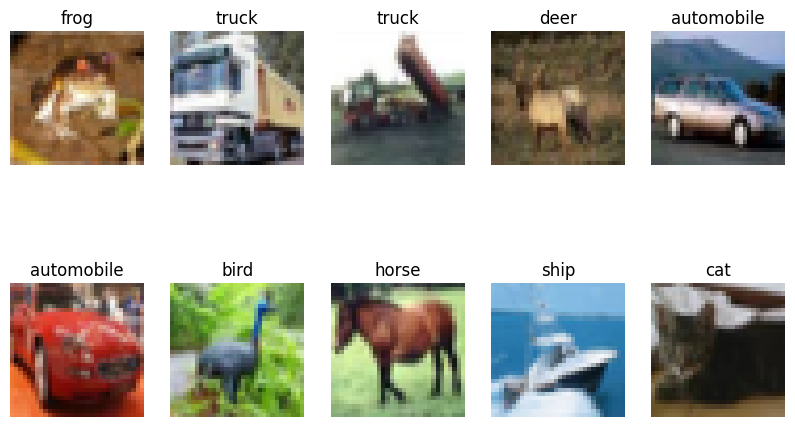

In [5]:
plt.figure(figsize=(10, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.show()

In [6]:
IMG_SIZE = 96

x_train = tf.image.resize(x_train, (IMG_SIZE, IMG_SIZE))
x_test = tf.image.resize(x_test, (IMG_SIZE, IMG_SIZE))

print(x_train.shape)
print(x_test.shape)

(50000, 96, 96, 3)
(10000, 96, 96, 3)


In [7]:
x_train = tf.cast(x_train, tf.float32) / 255.0
x_test = tf.cast(x_test, tf.float32) / 255.0

In [8]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

print("Pre-trained MobileNetV2 loaded.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Pre-trained MobileNetV2 loaded.


In [9]:
base_model.trainable = False

print("Trainable:", base_model.trainable)

Trainable: False


In [10]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96 (Functional)     │ (None, 3, 3, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/3
704/704 ━━━━━━━━━━━━━━━━━━━━ 130s 176ms/step - accuracy: 0.7100 - loss: 0.8412 - val_accuracy: 0.7768 - val_loss: 0.6324
Epoch 2/3
704/704 ━━━━━━━━━━━━━━━━━━━━ 128s 181ms/step - accuracy: 0.7772 - loss: 0.6440 - val_accuracy: 0.7938 - val_loss: 0.5804
Epoch 3/3
704/704 ━━━━━━━━━━━━━━━━━━━━ 132s 188ms/step - accuracy: 0.7917 - loss: 0.5927 - val_accuracy: 0.7930 - val_loss: 0.5872


In [13]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 78ms/step - accuracy: 0.7910 - loss: 0.6004
Test Loss: 0.6003780961036682
Test Accuracy: 0.7910000085830688


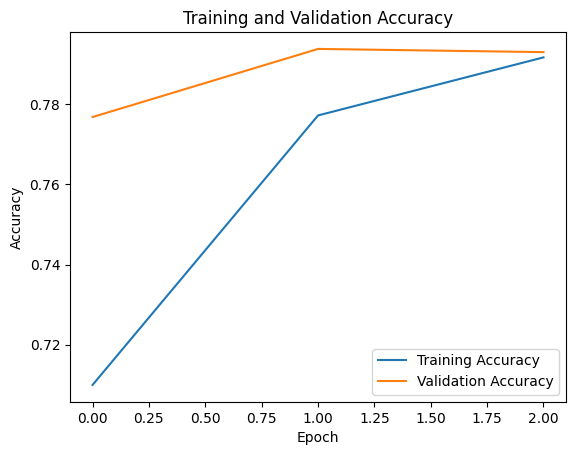

In [14]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [15]:
base_model.trainable = True

# Freeze all but the last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

Trainable layers: 20


In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
history_fine = model.fit(
    x_train,
    y_train,
    epochs=2,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 155s 204ms/step - accuracy: 0.7148 - loss: 0.8576 - val_accuracy: 0.7948 - val_loss: 0.6063
Epoch 2/2
704/704 ━━━━━━━━━━━━━━━━━━━━ 140s 198ms/step - accuracy: 0.7798 - loss: 0.6416 - val_accuracy: 0.8114 - val_loss: 0.5549


In [18]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Fine-tuned Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 24s 78ms/step - accuracy: 0.8029 - loss: 0.5827
Fine-tuned Test Accuracy: 0.8029000163078308


In [19]:
predictions = model.predict(x_test[:10])

predicted_classes = np.argmax(predictions, axis=1)

for i in range(10):
    print(
        "Actual:",
        class_names[y_test[i][0]],
        "| Predicted:",
        class_names[predicted_classes[i]]
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Actual: cat | Predicted: cat
Actual: ship | Predicted: ship
Actual: ship | Predicted: ship
Actual: airplane | Predicted: airplane
Actual: frog | Predicted: frog
Actual: frog | Predicted: frog
Actual: automobile | Predicted: automobile
Actual: frog | Predicted: deer
Actual: cat | Predicted: cat
Actual: automobile | Predicted: automobile


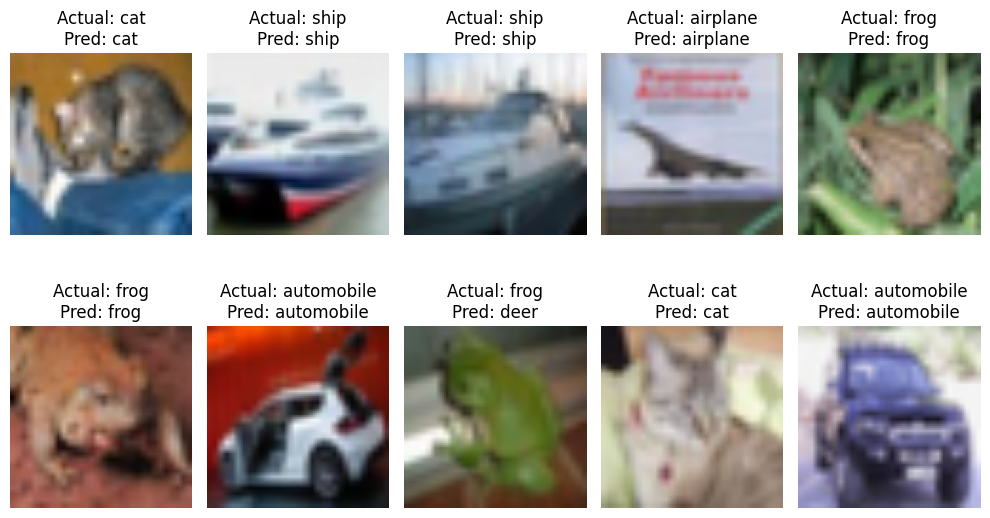

In [20]:
plt.figure(figsize=(10, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        f"Actual: {class_names[y_test[i][0]]}\n"
        f"Pred: {class_names[predicted_classes[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()